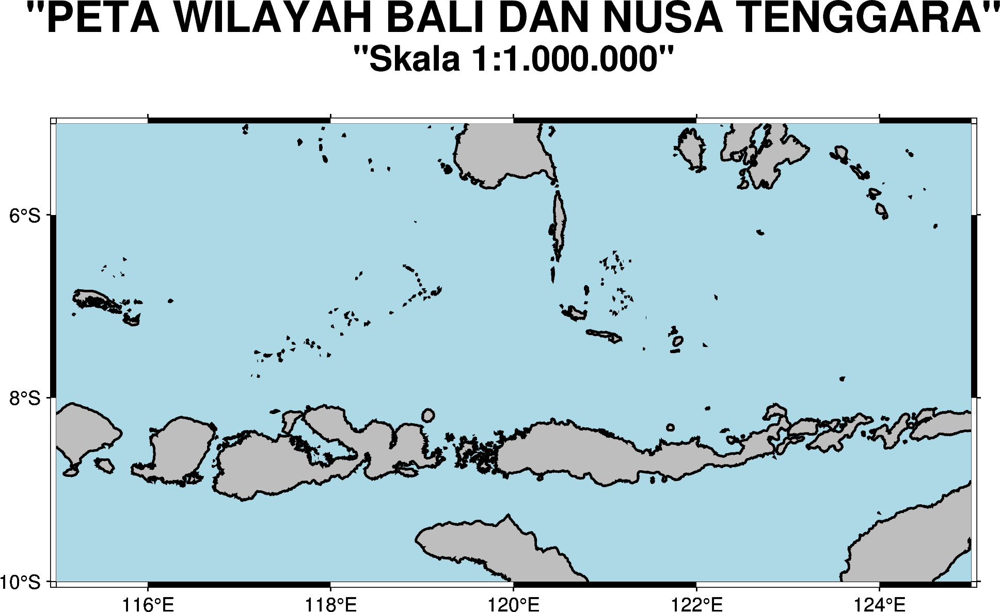

In [34]:
import pygmt

fig = pygmt.Figure()
fig.basemap(region=[115, 125, -10, -5], projection="M15c", frame=True)

# Judul utama + subtitle
fig.basemap(frame=["a", "+t\"PETA WILAYAH BALI DAN NUSA TENGGARA\"+s\"Skala 1:1.000.000\""])
fig.coast(shorelines="1p,black", water="lightblue", land="gray")

fig.show()

INI UNTUK PETA PGR 3

<>:114: SyntaxWarning: invalid escape sequence '\s'
<>:114: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Hype G12\AppData\Local\Temp\ipykernel_11724\2245102762.py:114: SyntaxWarning: invalid escape sequence '\s'
  cross = pd.read_csv('crsx.dat', delimiter='\s+', header=None)
c:\Python312\Lib\site-packages\pygmt\src\project.py:234: RuntimeWarning: Changing 'output_type' from 'pandas' to 'file' since 'outfile' parameter is set. Please use output_type='file' to suppress the warning.
  output_type = validate_output_table_type(output_type, outfile=outfile)
basemap [WARNING]: Option -B: Cannot use +f for Cartesian axes - modifier ignored
basemap [WARNING]: Option -B: Cannot use +f for Cartesian axes - modifier ignored


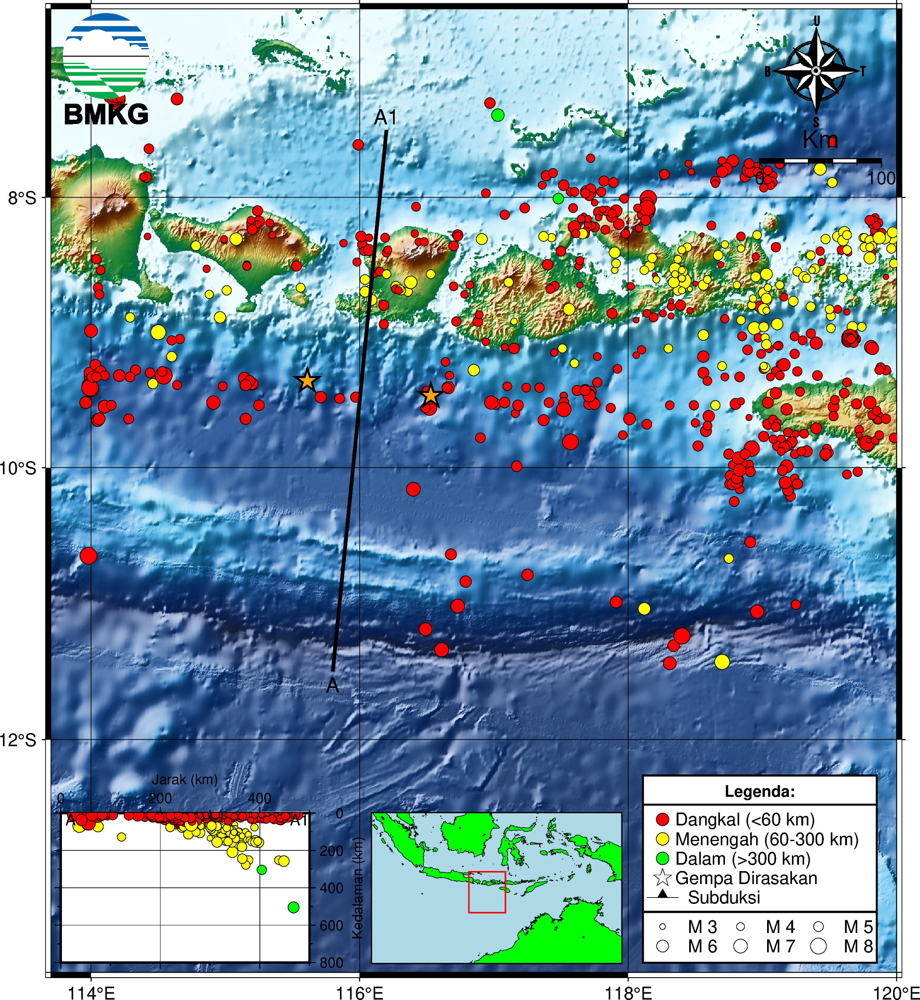

In [ ]:
import numpy as np
import pygmt
import pandas as pd

df = pd.read_csv('datalengkap.csv')

# Memilih kolom yang diinginkan
selected_columns = df[['Bujur','Lintang','Kedalaman', 'Magnitude']]

# Menulis data ke file DAT
with open('inputpeta.dat', 'w') as file:
    for index, row in selected_columns.iterrows():
        line = '  '.join(row.astype(str))  # Menggabungkan semua elemen baris menjadi satu string dengan spasi sebagai pemisah
        file.write(line + '\n')
        
# Membaca data dari hasil2.csv
data = pd.read_csv('datalengkap.csv')

# Buat figure
fig = pygmt.Figure()

# Buat color palette untuk kedalaman gempa
pygmt.makecpt(cmap="geo", series=[-8000, 4000])
pygmt.makecpt(cmap="red,yellow,green", series="0,60,300,1000", output="quakes.cpt")
data['Magnitude'] = pd.to_numeric(data['Magnitude'], errors='coerce')  # Ganti nilai tidak valid dengan NaN

# Menambahkan peta dasar dengan grid dan garis pantai
fig.grdimage(
    grid="D:/Seismioto/Bahan/earth_relief_15s.grd",
    region=[113.7, 120, -13.7, -6.6],
    projection="M17c",
    shading=True,
    frame=["xa2g2", "ya2g2"])#'+t"Peta Seismisitas"'])

# Plot gempa yang tidak dirasakan (kolom 'Dirasakan' kosong)
gempa_tidak_dirasakan = data[data['Dirasakan'].isna()]
if not gempa_tidak_dirasakan.empty:
    fig.plot(
        x=gempa_tidak_dirasakan['Bujur'],
        y=gempa_tidak_dirasakan['Lintang'],
        size=0.08*gempa_tidak_dirasakan['Magnitude'],
        style="cc",  # Lingkaran
        fill=gempa_tidak_dirasakan['Kedalaman'].astype(float),  # Warna berdasarkan kedalaman
        cmap="quakes.cpt",  # Gunakan colormap yang telah ditentukan
        pen="black"
    )
else:
    print("ada gempa bumi yang dirasakan untuk diplot.")

# Plot gempa yang dirasakan (kolom 'Dirasakan' terisi)
gempa_dirasakan = data[~data['Dirasakan'].isna()]
if not gempa_dirasakan.empty:
    fig.plot(
        x=gempa_dirasakan['Bujur'],
        y=gempa_dirasakan['Lintang'],
        size=0.1*gempa_dirasakan['Magnitude'],
        style="a0.5c",  # Simbol bintang
        fill="orange",  # Warna bintang merah
        pen="1p,black"  # Garis tepi hitam dengan ketebalan 1 point
    )
else:
    print("tidak ada gempa bumi yang dirasakan untuk diplot.")

fig.image('D:/Seismioto/Bahan/LogoBMKG.png', position='n0.01/0.88+w0.8i')
fig.image('D:/Seismioto/Bahan/mtangn.png', position='n0.83/0.87+w1i')
fig.basemap(map_scale="n0.91/0.84+w100k+f0.1p+lKm")
# fig.colorbar(
#     frame=["x+lKetinggian", "y"],  # Label untuk sumbu x dan y
#     position="n0.94/0.01+w2c/0.2c")  # Posisi colorbar (JMR = tengah-kanan), lebar 0.5 cm, panjang 10 cm
fig.legend(spec="D:/Seismioto/Bahan/legendageodi.gmt", position="n0.7/0.01+w4.7c",box="+gwhite+p1p,black")
with fig.inset(position="n0.38/0.01+w5c/3c", box="+pblack"):
    fig.coast(
        region=[97, 140, -22, 10],
        shorelines='0.2p,black',
        projection="M5c",
        land="green",
        water="lightblue"
    )
    fig.plot(x=[113.7, 120, 120, 113.7, 113.7], y=[-6.7, -6.7, -13.7, -13.7, -6.7], pen="0.7p,red", projection="M5c")
   

# Membuat cross section
fig.plot(x=[115.8, 116.2], y=[-11.5, -7.5], projection="M", pen=2)
fig.text(x=115.8, y=-11.6, text="A", font="12,Helvetica")
fig.text(x=116.2, y=-7.4, text="A1", font="12,Helvetica")
pygmt.project(
    data="inputpeta.dat",
    unit=True,
    center=[115.8, -11.5],
    endpoint=[116.2, -7.5],
    width=[-400, 400],
    convention="pz",
    outfile="crsx.dat"
)

fig.shift_origin(yshift=0.2, xshift=0.2)
fig.plot(
    x=[112, 112, 115.55, 115.55],  # Koordinat X dari sudut-sudut persegi
    y=[-12.6, -13.95, -13.95, -12.6],  # Koordinat Y dari sudut-sudut persegi
    fill="white",  # Warna latar belakang
    close=True  # Menutup jalur untuk membuat persegi berisi warna 
)

pygmt.config(FONT_LABEL="8p")

# Buat peta cross section dengan basemap
fig.basemap(
    projection="X5c/-3c",
    region=[0, 500, 0, 800],
    frame=['xafg+lJarak (km)+f2p', 'yafg+lKedalaman (km)+f2p', "wsEN"]
)

    # Membuat garis cross section   
cross = pd.read_csv('crsx.dat', delimiter='\s+', header=None)
# Define your column names
header = ['Distance', 'Dept', 'Mag']

# Assign the header
cross.columns = header

fig.plot(x=cross.Distance, 
            y=cross.Dept, 
            projection="X5/-3", 
            size =0.035 * (2 * cross.Mag), style="cc", 
            fill = cross.Dept, 
            cmap = "quakes.cpt", 
            pen = 'black'),
            #region = region_cs)
fig.text(x=20, y=35, text="A", font="9,Helvetica")
fig.text(x=480, y=35, text="A1", font="9,Helvetica")

fig.savefig('inipetanyaPGR3.png')
fig.show()

<>:111: SyntaxWarning: invalid escape sequence '\s'
<>:111: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Hype G12\AppData\Local\Temp\ipykernel_11724\2553291763.py:111: SyntaxWarning: invalid escape sequence '\s'
  cross = pd.read_csv('crsx.dat', delimiter='\s+', header=None)
c:\Python312\Lib\site-packages\pygmt\src\project.py:234: RuntimeWarning: Changing 'output_type' from 'pandas' to 'file' since 'outfile' parameter is set. Please use output_type='file' to suppress the warning.
  output_type = validate_output_table_type(output_type, outfile=outfile)
basemap [WARNING]: Option -B: Cannot use +f for Cartesian axes - modifier ignored
basemap [WARNING]: Option -B: Cannot use +f for Cartesian axes - modifier ignored


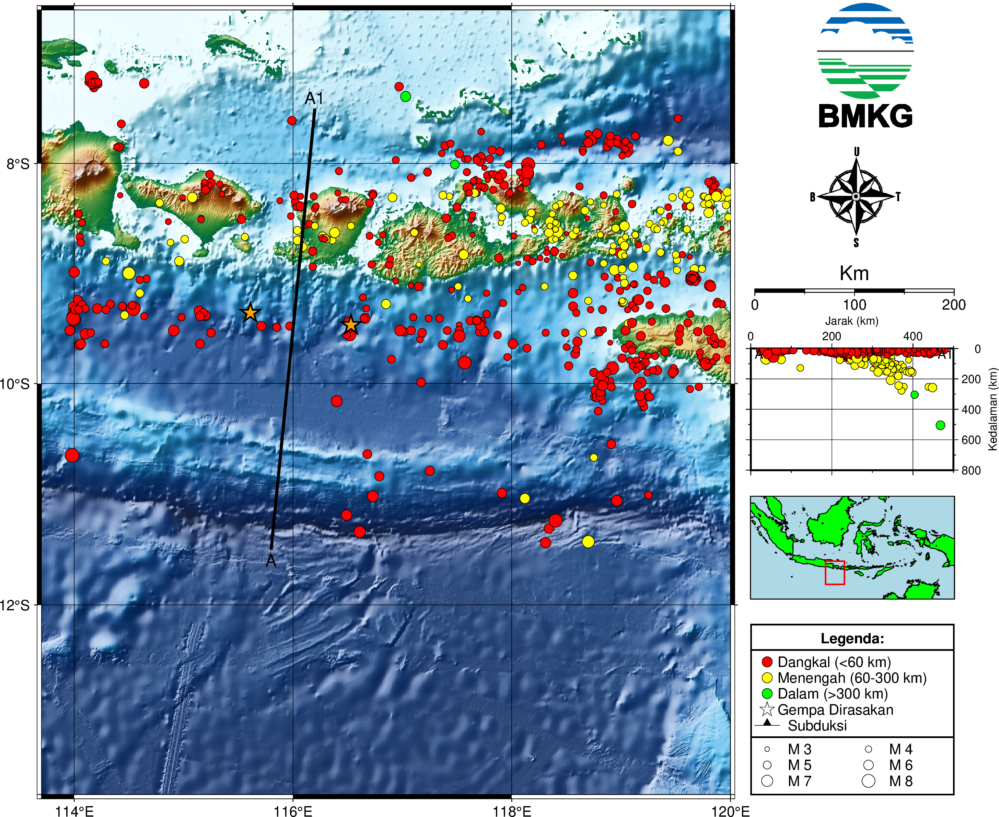

In [44]:
import numpy as np
import pygmt
import pandas as pd

df = pd.read_csv('datalengkap.csv')

# Memilih kolom yang diinginkan
selected_columns = df[['Bujur','Lintang','Kedalaman', 'Magnitude']]

# Menulis data ke file DAT
with open('inputpeta.dat', 'w') as file:
    for index, row in selected_columns.iterrows():
        line = '  '.join(row.astype(str))  # Menggabungkan semua elemen baris menjadi satu string dengan spasi sebagai pemisah
        file.write(line + '\n')
        
# Membaca data dari hasil2.csv
data = pd.read_csv('datalengkap.csv')

# Buat figure
fig = pygmt.Figure()

# Buat color palette untuk kedalaman gempa
pygmt.makecpt(cmap="geo", series=[-8000, 4000])
pygmt.makecpt(cmap="red,yellow,green", series="0,60,300,1000", output="quakes.cpt")
data['Magnitude'] = pd.to_numeric(data['Magnitude'], errors='coerce')  # Ganti nilai tidak valid dengan NaN

# Menambahkan peta dasar dengan grid dan garis pantai
fig.grdimage(
    grid="D:/Seismioto/Bahan/earth_relief_15s.grd",
    region=[113.7, 120, -13.7, -6.6],
    projection="M17c",
    shading=True,
    frame=["xa2g2", "ya2g2"])#'+t"Peta Seismisitas"'])

# Plot gempa yang tidak dirasakan (kolom 'Dirasakan' kosong)
gempa_tidak_dirasakan = data[data['Dirasakan'].isna()]
if not gempa_tidak_dirasakan.empty:
    fig.plot(
        x=gempa_tidak_dirasakan['Bujur'],
        y=gempa_tidak_dirasakan['Lintang'],
        size=0.08*gempa_tidak_dirasakan['Magnitude'],
        style="cc",  # Lingkaran
        fill=gempa_tidak_dirasakan['Kedalaman'].astype(float),  # Warna berdasarkan kedalaman
        cmap="quakes.cpt",  # Gunakan colormap yang telah ditentukan
        pen="black"
    )
else:
    print("ada gempa bumi yang dirasakan untuk diplot.")

# Plot gempa yang dirasakan (kolom 'Dirasakan' terisi)
gempa_dirasakan = data[~data['Dirasakan'].isna()]
if not gempa_dirasakan.empty:
    fig.plot(
        x=gempa_dirasakan['Bujur'],
        y=gempa_dirasakan['Lintang'],
        size=0.1*gempa_dirasakan['Magnitude'],
        style="a0.5c",  # Simbol bintang
        fill="orange",  # Warna bintang merah
        pen="1p,black"  # Garis tepi hitam dengan ketebalan 1 point
    )
else:
    print("tidak ada gempa bumi yang dirasakan untuk diplot.")

# Menambahkan colorbar
fig.image('D:/Seismioto/Bahan/LogoBMKG.png', position='n1.12/0.85+w1.1i')
fig.image('D:/Seismioto/Bahan/mtangn.png', position='n1.1/0.69+w1.1i')
fig.basemap(map_scale="n1.18/0.64+w200k+f0.1p+lKm")
with fig.inset(position="n1.03/0.25+w5c/2.5c", box="+pblack"):
    fig.coast(
        region=[97, 140, -15, 7],
        shorelines='0.5p,black',
        projection="M5c",
        land="green",
        water="lightblue"
    )
    fig.plot(x=[117.31, 113.21, 113.21, 117.31, 117.31], y=[-7, -7, -12, -12, -7], pen="1p,red")
fig.legend(spec="D:/Seismioto/Bahan/legenda.gmt", position="n1.03/0.0+w5c",box="+gwhite+p1p,black")
 
# Membuat cross section
fig.plot(x=[115.8, 116.2], y=[-11.5, -7.5], projection="M", pen=2)
fig.text(x=115.8, y=-11.6, text="A", font="12,Helvetica")
fig.text(x=116.2, y=-7.4, text="A1", font="12,Helvetica")
pygmt.project(
    data="inputpeta.dat",
    unit=True,
    center=[115.8, -11.5],
    endpoint=[116.2, -7.5],
    width=[-400, 400],
    convention="pz",
    outfile="crsx.dat"
)

fig.shift_origin(yshift=8, xshift=17.5)
fig.plot(
    x=[112, 112, 115.55, 115.55],  # Koordinat X dari sudut-sudut persegi
    y=[-12.6, -13.95, -13.95, -12.6],  # Koordinat Y dari sudut-sudut persegi
    fill="white",  # Warna latar belakang
    close=True  # Menutup jalur untuk membuat persegi berisi warna 
)

pygmt.config(FONT_LABEL="8p")

# Buat peta cross section dengan basemap
fig.basemap(
    projection="X5c/-3c",
    region=[0, 500, 0, 800],
    frame=['xafg+lJarak (km)+f2p', 'yafg+lKedalaman (km)+f2p', "wsEN"]
)

    # Membuat garis cross section   
cross = pd.read_csv('crsx.dat', delimiter='\s+', header=None)
# Define your column names
header = ['Distance', 'Dept', 'Mag']

# Assign the header
cross.columns = header

fig.plot(x=cross.Distance, 
            y=cross.Dept, 
            projection="X5/-3", 
            size =0.035 * (2 * cross.Mag), style="cc", 
            fill = cross.Dept, 
            cmap = "quakes.cpt", 
            pen = 'black'),
            #region = region_cs)
fig.text(x=20, y=35, text="A", font="9,Helvetica")
fig.text(x=480, y=35, text="A1", font="9,Helvetica")

fig.savefig('inipetanyaPGR3.png')
fig.show()

<>:124: SyntaxWarning: invalid escape sequence '\s'
<>:124: SyntaxWarning: invalid escape sequence '\s'
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14096\2153868778.py:124: SyntaxWarning: invalid escape sequence '\s'
  cross = pd.read_csv('crsx.dat', delimiter='\s+', header=None)
c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\pygmt\src\project.py:235: RuntimeWarning: Changing 'output_type' from 'pandas' to 'file' since 'outfile' parameter is set. Please use output_type='file' to silence this warning.
  output_type = validate_output_table_type(output_type, outfile=outfile)


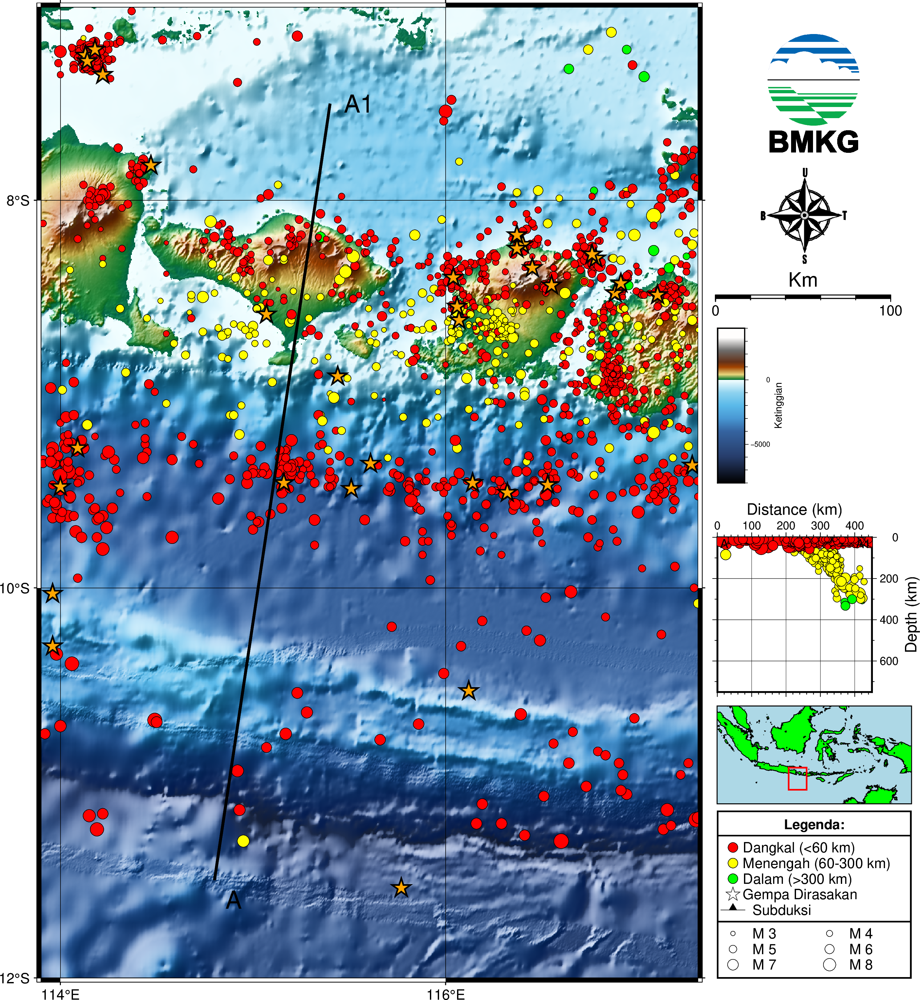

In [8]:
import numpy as np
import pygmt
import pandas as pd

input="DataGempa2025.xlsx"
df = pd.read_excel(input)

# Memilih kolom yang diinginkan
selected_columns = df[['Bujur','Lintang','Kedalaman', 'Magnitude']]

# Menulis data ke file DAT
with open('inputpeta.dat', 'w') as file:
    for index, row in selected_columns.iterrows():
        line = '  '.join(row.astype(str))  # Menggabungkan semua elemen baris menjadi satu string dengan spasi sebagai pemisah
        file.write(line + '\n')
        
# Membaca data dari hasil2.csv
data = pd.read_excel(input)

# Buat figure
fig = pygmt.Figure()

# Buat color palette untuk kedalaman gempa
pygmt.makecpt(cmap="geo", series=[-8000, 4000])
pygmt.makecpt(cmap="red,yellow,green", series="0,60,300,1000", output="quakes.cpt")
data['Magnitude'] = pd.to_numeric(data['Magnitude'], errors='coerce')  # Ganti nilai tidak valid dengan NaN

# Menambahkan peta dasar dengan grid dan garis pantai
fig.grdimage(
    grid="D:/Seismioto/Bahan/earth_relief_15s.grd",
    region=[113.9, 117.31, -12, -7],
    projection="M17c",
    shading=True,
    frame=["xa2g2", "ya2g2"])#'+t"Peta Seismisitas"'])

# Plot gempa yang tidak dirasakan (kolom 'Dirasakan' kosong)
gempa_tidak_dirasakan = data[data['Dirasakan'].isna()]
if not gempa_tidak_dirasakan.empty:
    fig.plot(
        x=gempa_tidak_dirasakan['Bujur'],
        y=gempa_tidak_dirasakan['Lintang'],
        size=0.08*gempa_tidak_dirasakan['Magnitude'],
        style="cc",  # Lingkaran
        fill=gempa_tidak_dirasakan['Kedalaman'].astype(float),  # Warna berdasarkan kedalaman
        cmap="quakes.cpt",  # Gunakan colormap yang telah ditentukan
        pen="black"
    )
else:
    print("ada gempa bumi yang dirasakan untuk diplot.")

# Plot gempa yang dirasakan (kolom 'Dirasakan' terisi)
gempa_dirasakan = data[~data['Dirasakan'].isna()]
if not gempa_dirasakan.empty:
    fig.plot(
        x=gempa_dirasakan['Bujur'],
        y=gempa_dirasakan['Lintang'],
        size=0.1*gempa_dirasakan['Magnitude'],
        style="a0.5c",  # Simbol bintang
        fill="orange",  # Warna bintang merah
        pen="1p,black"  # Garis tepi hitam dengan ketebalan 1 point
    )
else:
    print("tidak ada gempa bumi yang dirasakan untuk diplot.")

fig.plot(x=[114.8, 115.4], y=[-11.5, -7.5], projection="M", pen=2)
fig.text(x=114.9, y=-11.6, text="A", font="18,Helvetica")
fig.text(x=115.55, y=-7.5, text="A1", font="18,Helvetica")

# Menambahkan colorbar
fig.image('D:/Seismioto/Bahan/LogoBMKG.png', position='n1.1/0.85+w1.1i')
fig.image('D:/Seismioto/Bahan/mtangn.png', position='n1.08/0.73+w1.1i')
fig.basemap(map_scale="n1.16/0.7+w100k+f0.1p+lKm")
fig.colorbar(
    frame=["x+lKetinggian", "y"],  # Label untuk sumbu x dan y
    position="n1.03/0.51+w4c/0.7c")  # Posisi colorbar (JMR = tengah-kanan), lebar 0.5 cm, panjang 10 cm
with fig.inset(position="n1.03/0.18+w5c/2.5c", box="+pblack"):
    fig.coast(
        region=[97, 140, -15, 7],
        shorelines='0.5p,black',
        projection="M5c",
        land="green",
        water="lightblue"
    )
    fig.plot(x=[117.31, 113.21, 113.21, 117.31, 117.31], y=[-7, -7, -12, -12, -7], pen="1p,red")
fig.legend(spec="D:/Seismioto/Bahan/legenda.gmt", position="n1.03/0.0+w5c",box="+gwhite+p1p,black")

# fig.text(
#     text=f"Stasiun Geofisika \n"
#         "Denpasar",
#     x=118.3,  # di sebelah kanan (normalized coordinates)
#     y=-8.6,  # atas dari colorbar
#     font="20p,Helvetica-Bold,black",
#     justify="CM",  # Left-Middle alignment
#     no_clip=True  # Biar text tidak terpotong
# )

# Membuat cross section
pygmt.project(
    data="inputpeta.dat",
    unit=True,
    center=[114.8, -11.5],
    endpoint=[115.4, -7.5],
    width=[-200, 200],
    convention="pz",
    outfile="crsx.dat"
)

fig.shift_origin(yshift=7.4, xshift=17.5)
fig.plot(
    x=[113, 113, 114.18, 114.18],  # Koordinat X dari sudut-sudut persegi
    y=[-11.4, -12, -12, -11.4],  # Koordinat Y dari sudut-sudut persegi
    fill="white",  # Warna latar belakang
    close=True  # Menutup jalur untuk membuat persegi berisi warna 
)

# Buat peta cross section dengan basemap
fig.basemap(
    projection="X4c/-4c",
    region=[0, 450, 0, 750],
    frame=['xafg+lDistance (km)','yafg+lDepth (km)', "wsEN"]
)

    # Membuat garis cross section   
cross = pd.read_csv('crsx.dat', delimiter='\s+', header=None)
# Define your column names
header = ['Distance', 'Dept', 'Mag']

# Assign the header
cross.columns = header

fig.plot(x=cross.Distance, 
            y=cross.Dept, 
            projection="X4/-4", 
            size =0.035 * (2 * cross.Mag), style="cc", 
            fill = cross.Dept, 
            cmap = "quakes.cpt", 
            pen = 'black'),
            #region = region_cs)
fig.text(x=20, y=30, text="A", font="9,Helvetica")
fig.text(x=425, y=30, text="A1", font="9,Helvetica")

fig.savefig('inipetanya.png')
fig.show()

tidak ada gempa bumi yang dirasakan untuk diplot.


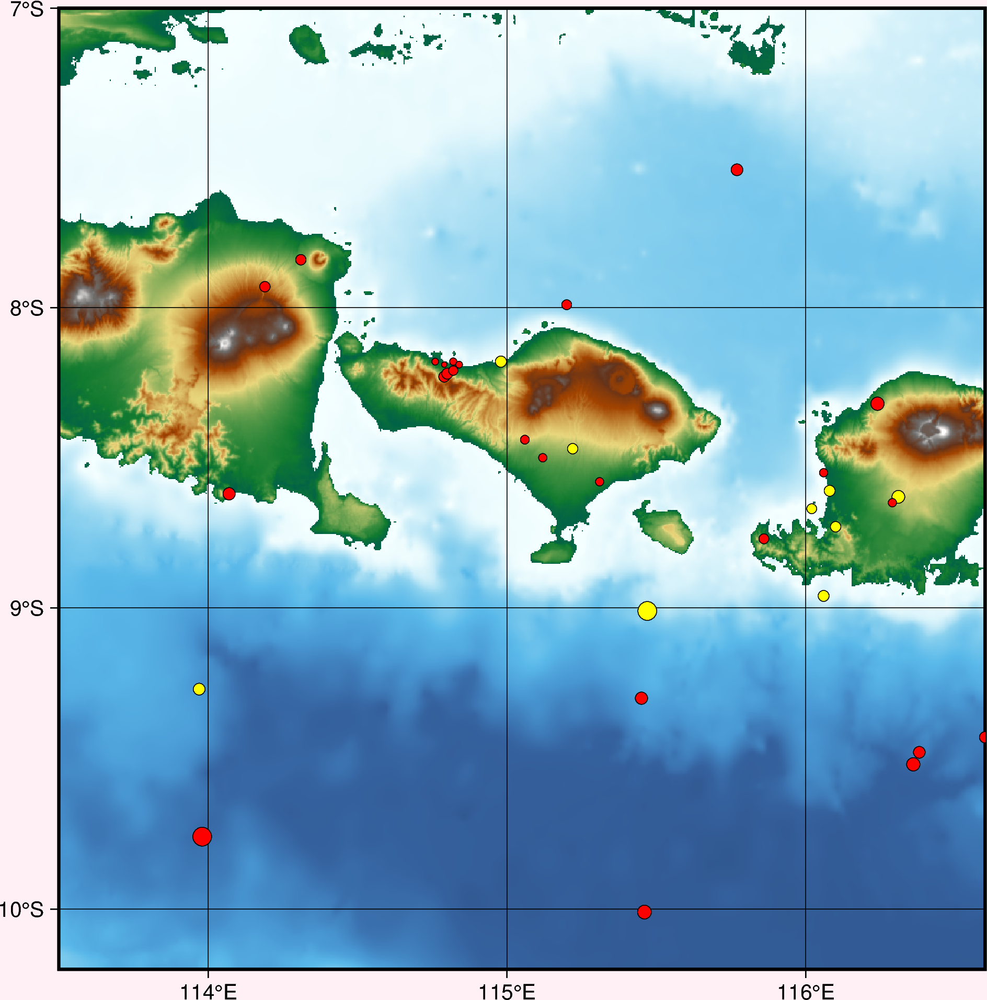

In [2]:
import numpy as np
import pygmt
import pandas as pd

input="datalengkap.csv"
df = pd.read_csv(input)

# Memilih kolom yang diinginkan
selected_columns = df[['Bujur','Lintang','Kedalaman', 'Magnitude']]

# Menulis data ke file DAT
with open('inputpeta.dat', 'w') as file:
    for index, row in selected_columns.iterrows():
        line = '  '.join(row.astype(str))  # Menggabungkan semua elemen baris menjadi satu string dengan spasi sebagai pemisah
        file.write(line + '\n')
        
# Membaca data dari hasil2.csv
data = pd.read_csv(input)

# Buat figure
fig = pygmt.Figure()

# Buat color palette untuk kedalaman gempa
pygmt.makecpt(cmap="geo", series=[-8000, 4000])
pygmt.makecpt(cmap="red,yellow,green", series="0,60,300,1000", output="quakes.cpt")
data['Magnitude'] = pd.to_numeric(data['Magnitude'], errors='coerce')  # Ganti nilai tidak valid dengan NaN

#Menambahkan peta dasar dengan grid dan garis pantai
fig.grdimage(
    grid="D:/Seismioto/Bahan/earth_relief_15s.grd",
    region=[113.5, 116.6, -10.2, -7],
    projection="M15c",
    #shading=True,
    frame=["xa1g1", "ya1g1"])

# fig.coast(
#     region=[115.4, 116, -8.8, -8.2],
#     projection="M15c",
#     frame=["xa0.2g2", "ya0.2g2",'+t"Peta Seismisitas Karangasem 1-6 Jan 2025"'],
#     land='white',
#     water="lightblue",
#     shorelines="1/0.1p,black",
#     resolution='f'
# )

# Plot gempa yang tidak dirasakan (kolom 'Dirasakan' kosong)
gempa_tidak_dirasakan = data[data['Dirasakan'].isna()]
if not gempa_tidak_dirasakan.empty:
    fig.plot(
        x=gempa_tidak_dirasakan['Bujur'],
        y=gempa_tidak_dirasakan['Lintang'],
        size=0.08*gempa_tidak_dirasakan['Magnitude'],
        style="cc",  # Lingkaran
        fill=gempa_tidak_dirasakan['Kedalaman'].astype(float),  # Warna berdasarkan kedalaman
        cmap="quakes.cpt",  # Gunakan colormap yang telah ditentukan
        pen="black"
    )
else:
    print("ada gempa bumi yang dirasakan untuk diplot.")

# Plot gempa yang dirasakan (kolom 'Dirasakan' terisi)
gempa_dirasakan = data[~data['Dirasakan'].isna()]
if not gempa_dirasakan.empty:
    fig.plot(
        x=gempa_dirasakan['Bujur'],
        y=gempa_dirasakan['Lintang'],
        size=0.1*gempa_dirasakan['Magnitude'],
        style="a0.5c",  # Simbol bintang
        fill="orange",  # Warna bintang merah
        pen="1p,black"  # Garis tepi hitam dengan ketebalan 1 point
    )
else:
    print("tidak ada gempa bumi yang dirasakan untuk diplot.")

# fig.plot(x=[114.8, 115.4], y=[-11.5, -7.5], projection="M", pen=2)
# fig.text(x=114.9, y=-11.6, text="A", font="18,Helvetica")
# fig.text(x=115.55, y=-7.5, text="A1", font="18,Helvetica")

# # Menambahkan colorbar
# fig.image('D:/Seismioto/Bahan/LogoBMKG.png', position='n1.1/0.85+w1.1i')
# fig.image('D:/Seismioto/Bahan/mtangn.png', position='n1.08/0.73+w1.1i')
# #fig.basemap(map_scale="n1.16/0.7+w100k+f0.1p+lKm")
# fig.colorbar(
#     frame=["x+lKetinggian", "y"],  # Label untuk sumbu x dan y
#     position="n1.03/0.51+w4c/0.7c")  # Posisi colorbar (JMR = tengah-kanan), lebar 0.5 cm, panjang 10 cm
# with fig.inset(position="n1.03/0.18+w5c/2.5c", box="+pblack"):
#     fig.coast(
#         region=[97, 140, -15, 7],
#         shorelines='0.5p,black',
#         projection="M5c",
#         land="green",
#         water="lightblue"
#     )
#     fig.plot(x=[117.31, 113.21, 113.21, 117.31, 117.31], y=[-7, -7, -12, -12, -7], pen="1p,red")
#fig.legend(spec="D:/Seismioto/Bahan/legenda.gmt", position="n0.66/0.01+w5c",box="+gwhite+p1p,black")

# fig.text(
#     text=f"Stasiun Geofisika \n"
#         "Denpasar",
#     x=118.3,  # di sebelah kanan (normalized coordinates)
#     y=-8.6,  # atas dari colorbar
#     font="20p,Helvetica-Bold,black",
#     justify="CM",  # Left-Middle alignment
#     no_clip=True  # Biar text tidak terpotong
# )

# # Membuat cross section
# pygmt.project(
#     data="inputpeta.dat",
#     unit=True,
#     center=[114.8, -11.5],
#     endpoint=[115.4, -7.5],
#     width=[-200, 200],
#     convention="pz",
#     outfile="crsx.dat"
# )

# fig.shift_origin(yshift=7.4, xshift=17.5)
# fig.plot(
#     x=[113, 113, 114.18, 114.18],  # Koordinat X dari sudut-sudut persegi
#     y=[-11.4, -12, -12, -11.4],  # Koordinat Y dari sudut-sudut persegi
#     fill="white",  # Warna latar belakang
#     close=True  # Menutup jalur untuk membuat persegi berisi warna 
# )

# # Buat peta cross section dengan basemap
# fig.basemap(
#     projection="X4c/-4c",
#     region=[0, 450, 0, 750],
#     frame=['xafg+lDistance (km)','yafg+lDepth (km)', "wsEN"]
# )

#     # Membuat garis cross section   
# cross = pd.read_csv('crsx.dat', delimiter='\s+', header=None)
# # Define your column names
# header = ['Distance', 'Dept', 'Mag']

# # Assign the header
# cross.columns = header

# fig.plot(x=cross.Distance, 
#             y=cross.Dept, 
#             projection="X4/-4", 
#             size =0.035 * (2 * cross.Mag), style="cc", 
#             fill = cross.Dept, 
#             cmap = "quakes.cpt", 
#             pen = 'black'),
#             #region = region_cs)
# fig.text(x=20, y=30, text="A", font="9,Helvetica")
# fig.text(x=425, y=30, text="A1", font="9,Helvetica")

#fig.savefig('krgsm6jan.png')
fig.show()